# Avocado price - JarvisTEC (`avocado`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Avocado Prices (Kaggle, neuromusic/avocado-prices)](https://www.kaggle.com/datasets/neuromusic/avocado-prices), weekly retail prices and sales of Hass avocados in the United States from January 2015 to March 2018. According to the dataset description, it is retail scan data from the Hass Avocado Board.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import math
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "avocado"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/avocado/avocado.csv"
TARGET_COLUMN = "average_price"  # USD per avocado, weekly average
TASK_TYPE = "regression"  # "classification" or "regression"
IS_TIME_SERIES = True  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = "date"  # date column name when IS_TIME_SERIES is True
# Same-week sales figures: unknown when next week is forecast (leakage).
EXCLUDED_COLUMNS = [
    "total_volume", "plu_4046", "plu_4225", "plu_4770",
    "total_bags", "small_bags", "large_bags", "xlarge_bags", "year",
]
# Series served by the backend: the national aggregate.
SERVED_REGION = "TotalUS"
TEST_FRACTION = 0.2  # most recent weeks
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to **forecast the average retail price of a Hass avocado for the next week**, in US dollars (USD) per unit, from the prices of the previous weeks.

**Assumed user and cost of an error** (an assumption of this notebook, not something measured in the data): the forecast is meant for a buyer or a retailer who plans next week's purchases or promotions. If the forecast is too high, the buyer may buy early or set a shelf price above the market; if it is too low, the budget falls short or a promotion is planned at a price that no longer covers the cost. Both directions are treated as equally costly, which is why symmetric error metrics (RMSE and MAE) are used.

- **Task type:** time-series forecasting, framed as supervised regression with **lag features**. Each row is one week of one series; the target is the price of that week, and the inputs are the prices of the four previous weeks, the week of the year and the avocado type. The forecast horizon is **one week**.
- **Scope:** the dataset has 108 weekly series (54 regions x 2 types). The model is **trained on all of them** (one row per region, type and week, with the lags computed inside each series) and **served for the national series** (`TotalUS`), conventional or organic. A model trained on the two national series alone would have about 330 rows; pooling all the series gives about 17,800 rows. The region is **not** an input: the price level of each series is already carried by its own past prices, and the API stays simple (a type and, optionally, the user's own recent prices).
- **No leakage:** the sales volume and the bag counts of a week belong to the same week as its price, so they are not known when the forecast is made. They are described in sections 2 and 3 but are **never inputs**. Only earlier weeks of the same series are used.
- **Success metrics:** root mean squared error (**RMSE**) and mean absolute error (**MAE**) in USD, mean absolute percentage error (**MAPE**, comparable between the cheaper conventional and the more expensive organic avocado) and the coefficient of determination (**R2**). In forecasting, the reference is not the mean but the **naive forecast** "next week = this week" (Hyndman & Athanasopoulos, 2021): a model is useful only if it beats that forecast on the test weeks. The split is strictly chronological.
- **Support:** Hyndman and Athanasopoulos (2021) describe the naive and seasonal-naive benchmarks, lagged predictors and time-series cross-validation used here. Makridakis et al. (2018) compare statistical and machine-learning forecasting methods and raise concerns about how the latter perform against simple statistical benchmarks. This notebook asks the same question of the avocado data.

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH, index_col=0)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (18249, 13)


,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


In [3]:
# snake_case names. The three PLU columns are the units sold of each Hass
# size code (4046 small, 4225 large, 4770 extra large).
df = df.rename(columns={
    "Date": "date", "AveragePrice": "average_price",
    "Total Volume": "total_volume", "4046": "plu_4046", "4225": "plu_4225",
    "4770": "plu_4770", "Total Bags": "total_bags",
    "Small Bags": "small_bags", "Large Bags": "large_bags",
    "XLarge Bags": "xlarge_bags",
})
df[DATE_COLUMN] = pd.to_datetime(df[DATE_COLUMN])
df = df.sort_values([DATE_COLUMN, "region", "type"]).reset_index(drop=True)
display(df.head())

weeks = pd.DatetimeIndex(sorted(df[DATE_COLUMN].unique()))
print("First week:", weeks[0].date(), "| last week:", weeks[-1].date())
print("Distinct weeks:", len(weeks))
print("Days between consecutive weeks:",
      pd.Series(weeks).diff().dt.days.dropna().unique().tolist())
print("Weekday of the dates:", df[DATE_COLUMN].dt.day_name().unique().tolist())
print("Regions:", df["region"].nunique(), "| types:",
      df["type"].unique().tolist())
series_length = df.groupby(["region", "type"]).size()
print("Series (region, type):", len(series_length))
print("Series with missing weeks:")
display(series_length[series_length < len(weeks)])
print("Repeated (date, region, type):",
      df.duplicated([DATE_COLUMN, "region", "type"]).sum())

,date,average_price,total_volume,plu_4046,plu_4225,plu_4770,total_bags,small_bags,large_bags,xlarge_bags,type,year,region
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany
1,2015-01-04,1.79,1373.95,57.42,153.88,0.00,1162.65,1162.65,0.00,0.0,organic,2015,Albany
2,2015-01-04,1.00,435021.49,364302.39,23821.16,82.15,46815.79,16707.15,30108.64,0.0,conventional,2015,Atlanta
3,2015-01-04,1.76,3846.69,1500.15,938.35,0.00,1408.19,1071.35,336.84,0.0,organic,2015,Atlanta
4,2015-01-04,1.08,788025.06,53987.31,552906.04,39995.03,141136.68,137146.07,3990.61,0.0,conventional,2015,BaltimoreWashington


First week: 2015-01-04 | last week: 2018-03-25
Distinct weeks: 169
Days between consecutive weeks: [7.0]
Weekday of the dates: ['Sunday']
Regions: 54 | types: ['conventional', 'organic']
Series (region, type): 108
Series with missing weeks:


region            type   
WestTexNewMexico  organic    166
dtype: int64

Repeated (date, region, type): 0


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
date,datetime64[us],0,0.0,169
average_price,float64,0,0.0,259
total_volume,float64,0,0.0,18237
plu_4046,float64,0,0.0,17702
plu_4225,float64,0,0.0,18103
plu_4770,float64,0,0.0,12071
total_bags,float64,0,0.0,18097
small_bags,float64,0,0.0,17321
large_bags,float64,0,0.0,15082
xlarge_bags,float64,0,0.0,5588


Duplicated rows: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,18249,NaN,NaN,NaN,2016-08-13 23:30:43.498274,2015-01-04 00:00:00,2015-10-25 00:00:00,2016-08-14 00:00:00,2017-06-04 00:00:00,2018-03-25 00:00:00,NaN
average_price,18249.0,NaN,NaN,NaN,1.405978,0.44,1.1,1.37,1.66,3.25,0.402677
total_volume,18249.0,NaN,NaN,NaN,850644.013009,84.56,10838.58,107376.76,432962.29,62505646.52,3453545.355399
plu_4046,18249.0,NaN,NaN,NaN,293008.424531,0.0,854.07,8645.3,111020.2,22743616.17,1264989.081763
plu_4225,18249.0,NaN,NaN,NaN,295154.568356,0.0,3008.78,29061.02,150206.86,20470572.61,1204120.401135
plu_4770,18249.0,NaN,NaN,NaN,22839.735993,0.0,0.0,184.99,6243.42,2546439.11,107464.068435
total_bags,18249.0,NaN,NaN,NaN,239639.20206,0.0,5088.64,39743.83,110783.37,19373134.37,986242.399216
small_bags,18249.0,NaN,NaN,NaN,182194.686696,0.0,2849.42,26362.82,83337.67,13384586.8,746178.514962
large_bags,18249.0,NaN,NaN,NaN,54338.088145,0.0,127.47,2647.71,22029.25,5719096.61,243965.964547
xlarge_bags,18249.0,NaN,NaN,NaN,3106.426507,0.0,0.0,0.0,132.5,551693.65,17692.894652


**Data description.** According to the dataset description, this is weekly retail scan data compiled by the Hass Avocado Board from the sales of US retailers. The file has **18,249 rows** and 13 columns (after dropping its row counter). Each row is one week of one region and one avocado type. The meaning of the sales columns below is taken from the dataset description and was not verified independently:

| Variable | Meaning | Type / unit |
|---|---|---|
| `date` | date of the observation (always a Sunday) | date, 2015-01-04 to 2018-03-25 |
| `average_price` | average price of one avocado that week (**target**) | USD per unit |
| `total_volume` | avocados sold | units |
| `plu_4046`, `plu_4225`, `plu_4770` | avocados sold under each price look-up (PLU) code; according to the dataset description, the codes correspond to small, large and extra-large Hass avocados | units |
| `total_bags`, `small_bags`, `large_bags`, `xlarge_bags` | avocados sold in bags, by bag size | units |
| `type` | `conventional` or `organic` | categorical |
| `year` | year of the date | integer, 2015-2018 |
| `region` | city, larger region or the national total (`TotalUS`) | categorical, 54 values |

**Structure of the series:**
- **169 weeks**, exactly 7 days apart, with no gap in the calendar.
- **108 series** (54 regions x 2 types). 107 of them have all 169 weeks; `WestTexNewMexico` organic has 166 (three weeks missing).
- The regions overlap: according to the dataset description, `TotalUS` and the larger regions aggregate the cities, so the rows are not independent markets.

**Data quality:**
- **Missing values:** none. **Duplicates:** no duplicated rows and no repeated (date, region, type) combination.
- **Missing weeks:** the three missing weeks are handled when the lags are built. Every series is aligned to the full weekly calendar, and a row is dropped when its target or one of its four lags is missing. "Lag 1" therefore always means "one week before".
- **Order:** the file is not sorted by date (its first rows go backwards from December 2015), so it is sorted before anything else.
- **Price range:** from 0.44 to 3.25 USD, plausible for retail prices; no value is removed.
- **Volumes are extremely skewed** (median 107,377 units per week, maximum 62.5 million) because cities and the national total share the same column.
- `year` duplicates `date`, and the volume and bag columns are same-week information: all of them are excluded from the inputs.

## 3. Data exploration

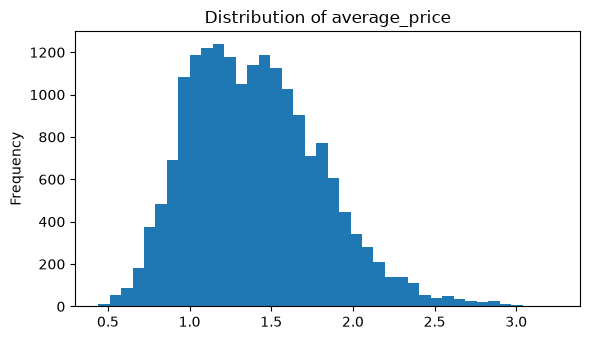

In [5]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

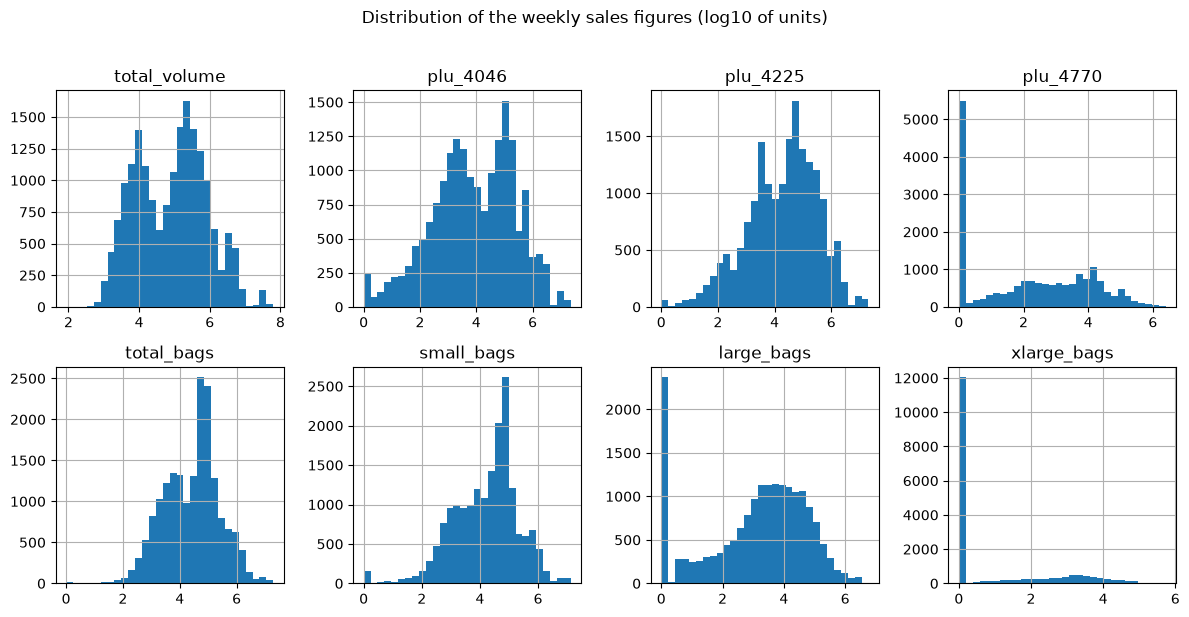

In [6]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    # Sales figures are described here but are never model inputs.
    if c not in [target, "year"]
]
rows = (len(numeric_columns) + 3) // 4
np.log10(df[numeric_columns] + 1).hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of the weekly sales figures (log10 of units)", y=1.02)
plt.tight_layout()
plt.show()

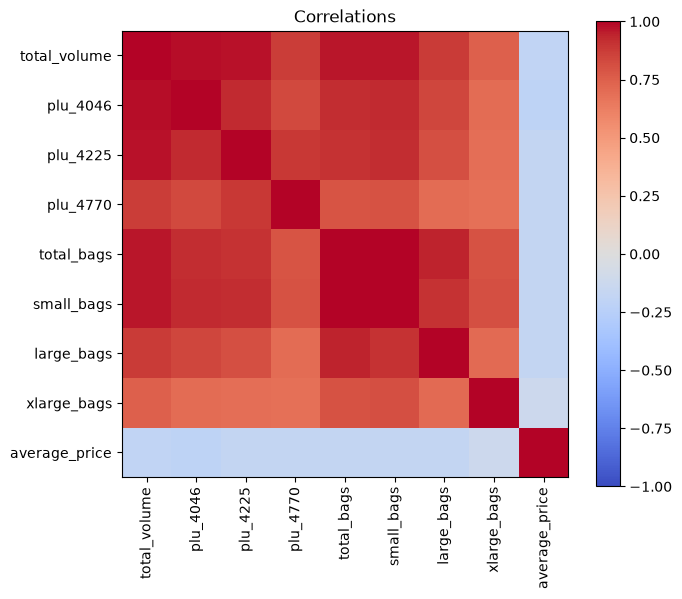

plu_4046       -0.208317
total_volume   -0.192752
plu_4770       -0.179446
total_bags     -0.177088
small_bags     -0.174730
large_bags     -0.172940
plu_4225       -0.172928
xlarge_bags    -0.117592
Name: correlation with the target, dtype: float64

In [7]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

In [8]:
categorical_columns = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in EXCLUDED_COLUMNS + [target, DATE_COLUMN]
]
for column in categorical_columns[:6]:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().head(10))


type: 2 categories


type
conventional    9126
organic         9123
Name: count, dtype: int64


region: 54 categories


region
Albany                 338
Atlanta                338
BaltimoreWashington    338
Boise                  338
Boston                 338
BuffaloRochester       338
California             338
Charlotte              338
Chicago                338
CincinnatiDayton       338
Name: count, dtype: int64

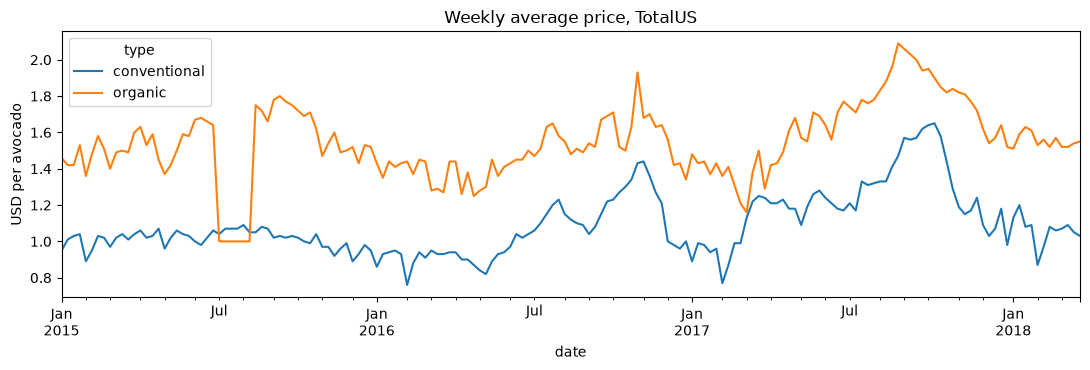

type,conventional,organic
count,169.000,169.000
mean,1.092,1.546
std,0.174,0.203
min,0.760,1.000
25%,0.970,1.430
50%,1.040,1.530
75%,1.190,1.670
max,1.650,2.090


type,conventional,organic
year,,
2015,1.012,1.502
2016,1.047,1.480
2017,1.222,1.652
2018,1.060,1.554


Highest national price per type:


,date,price
type,,
conventional,2017-10-08,1.65
organic,2017-08-27,2.09


In [9]:
# The series over time: national average price of each type.
national = (
    df[df["region"].eq(SERVED_REGION)]
    .pivot(index=DATE_COLUMN, columns="type", values=target)
)
fig, ax = plt.subplots(figsize=(11, 3.8))
national.plot(ax=ax)
ax.set_title(f"Weekly average price, {SERVED_REGION}")
ax.set_ylabel("USD per avocado")
plt.tight_layout()
plt.show()

display(national.describe().round(3))
display(national.groupby(national.index.year).mean().round(3)
        .rename_axis("year"))
print("Highest national price per type:")
display(pd.DataFrame({
    "date": national.idxmax().dt.date, "price": national.max(),
}))

month,1,2,3,4,5,6,7,8,9,10,11,12
type,,,,,,,,,,,,
conventional,0.957,0.917,1.052,1.062,1.025,1.078,1.166,1.180,1.242,1.301,1.142,1.003
organic,1.431,1.410,1.392,1.474,1.484,1.597,1.472,1.609,1.796,1.742,1.644,1.511


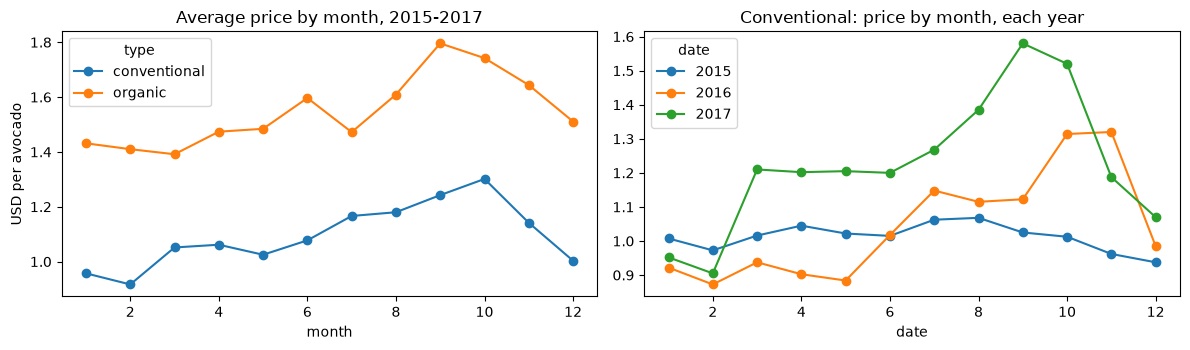

Cheapest / dearest month per type:


,cheapest,dearest,range_usd
type,,,
conventional,2,10,0.385
organic,3,9,0.404


In [10]:
# Seasonality: average price by calendar month (2015-2017, complete years).
complete = national[national.index.year <= 2017]
by_month = complete.groupby(complete.index.month).mean().rename_axis("month")
display(by_month.round(3).T)
by_month_year = (
    complete["conventional"]
    .groupby([complete.index.year, complete.index.month]).mean()
    .unstack(0)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
by_month.plot(ax=axes[0], marker="o")
axes[0].set_title("Average price by month, 2015-2017")
axes[0].set_ylabel("USD per avocado")
by_month_year.plot(ax=axes[1], marker="o")
axes[1].set_title("Conventional: price by month, each year")
plt.tight_layout()
plt.show()
print("Cheapest / dearest month per type:")
display(pd.DataFrame({
    "cheapest": by_month.idxmin(), "dearest": by_month.idxmax(),
    "range_usd": (by_month.max() - by_month.min()).round(3),
}))

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
conventional,9126.0,1.158,0.263,0.46,0.98,1.13,1.32,2.22
organic,9123.0,1.654,0.364,0.44,1.42,1.63,1.87,3.25


National organic premium (USD): mean 0.454 | min -0.09 | max 0.77
Weeks where organic is cheaper than conventional (national): 6
Correlation between the two national series: 0.65
Share of the national volume:


type
conventional    97.21
organic          2.79
Name: total_volume, dtype: float64

type,conventional,organic
region,,
PhoenixTucson,0.728,1.721
Houston,0.825,1.271
WestTexNewMexico,0.842,1.689
DallasFtWorth,0.846,1.325
Philadelphia,1.396,1.868
SanFrancisco,1.397,2.211
NewYork,1.402,2.053
HartfordSpringfield,1.408,2.229


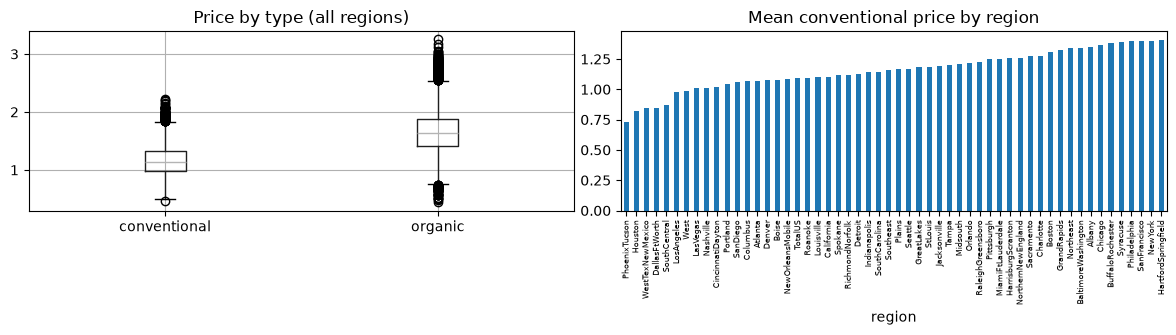

Correlation price vs. same-week log volume, within each series:


type
conventional   -0.546
organic        -0.397
Name: median correlation, dtype: float64

In [11]:
# Conventional vs. organic, and the spread across regions.
display(df.groupby("type")[target].describe().round(3))
premium = national["organic"] - national["conventional"]
print("National organic premium (USD): mean", round(premium.mean(), 3),
      "| min", round(premium.min(), 3), "| max", round(premium.max(), 3))
print("Weeks where organic is cheaper than conventional (national):",
      int((premium < 0).sum()))
print("Correlation between the two national series:",
      round(national["conventional"].corr(national["organic"]), 3))
volume = df[df["region"].eq(SERVED_REGION)].groupby("type")["total_volume"]
print("Share of the national volume:")
display((volume.sum() / volume.sum().sum() * 100).round(2))

by_region = (
    df.groupby(["region", "type"])[target].mean().unstack().round(3)
    .sort_values("conventional")
)
display(pd.concat([by_region.head(4), by_region.tail(4)]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
df.boxplot(column=target, by="type", ax=axes[0])
axes[0].set_title("Price by type (all regions)")
axes[0].set_xlabel("")
by_region["conventional"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean conventional price by region")
axes[1].tick_params(axis="x", labelsize=6)
plt.suptitle("")
plt.tight_layout()
plt.show()

# Why same-week volume is not an input: it moves with the price of the
# SAME week, which is exactly what is unknown when forecasting.
print("Correlation price vs. same-week log volume, within each series:")
within = df.groupby(["region", "type"]).apply(
    lambda g: g[target].corr(np.log1p(g["total_volume"]))
)
display(within.groupby("type").median().round(3)
        .rename("median correlation"))

,TotalUS conventional,TotalUS organic,regional series (median)
lag (weeks),,,
1,0.926,0.846,0.820
2,0.857,0.721,0.734
3,0.793,0.626,0.680
4,0.716,0.531,0.611
8,0.456,0.268,0.395
13,0.255,0.155,0.207
26,0.044,-0.107,-0.044
52,0.435,0.224,0.097


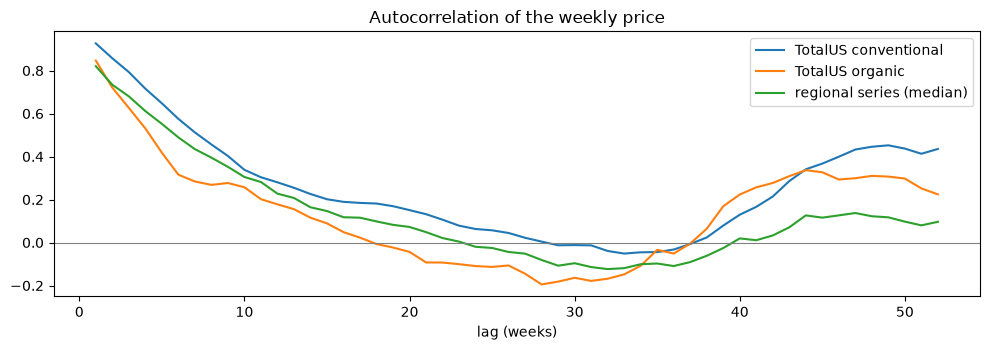

,mean abs weekly change,std of weekly change,autocorr of the change (lag 1)
TotalUS conventional,0.049,0.067,-0.027
TotalUS organic,0.071,0.113,-0.092
regional series,0.113,0.171,-0.260


In [12]:
# Autocorrelation of the price: how much does last week tell about this one?
LAGS = [1, 2, 3, 4, 8, 13, 26, 52]
acf = pd.DataFrame({
    f"{SERVED_REGION} {kind}": [
        national[kind].autocorr(lag) for lag in range(1, 53)
    ]
    for kind in national.columns
}, index=range(1, 53))
wide = df.pivot_table(
    index=DATE_COLUMN, columns=["region", "type"], values=target
)
regional = wide.drop(columns=SERVED_REGION, level="region")
acf["regional series (median)"] = [
    regional.apply(lambda s: s.autocorr(lag)).median()
    for lag in range(1, 53)
]
display(acf.loc[LAGS].round(3).rename_axis("lag (weeks)"))
fig, ax = plt.subplots(figsize=(10, 3.6))
acf.plot(ax=ax)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("lag (weeks)")
ax.set_title("Autocorrelation of the weekly price")
plt.tight_layout()
plt.show()

# Week-to-week change: the error of the naive forecast "same as last week".
change = wide.diff()
rows = {}
for label, columns in {
    f"{SERVED_REGION} conventional": [(SERVED_REGION, "conventional")],
    f"{SERVED_REGION} organic": [(SERVED_REGION, "organic")],
    "regional series": regional.columns.tolist(),
}.items():
    values = change[columns].stack([0, 1], future_stack=True).dropna()
    lag1 = np.nanmedian([
        change[column].autocorr(1) for column in columns
    ])
    rows[label] = {
        "mean abs weekly change": values.abs().mean(),
        "std of weekly change": values.std(),
        "autocorr of the change (lag 1)": lag1,
    }
display(pd.DataFrame(rows).T.round(3))

**Exploration findings:**

- **Target distribution:** over all rows the price goes from 0.44 to 3.25 USD, with a mean of 1.41 USD, a median of 1.37 USD and a standard deviation of 0.40 USD; half of the rows lie between 1.10 and 1.66 USD. The mean is slightly above the median and the maximum is farther from the median than the minimum, so the distribution has a longer right tail. The histogram pools the two types, whose means differ (see *Conventional vs. organic* below).
- **Sales volumes:** the sales columns are extremely right-skewed (`total_volume` has a median of 107,377 units, a mean of 850,644 and a maximum of 62.5 million), which is why their histograms use a logarithmic scale. Some columns are zero in many rows: the median of `xlarge_bags` is 0 and the first quartile of `plu_4770` is 0.
- **Correlations with the price:** over the pooled rows, all eight sales columns are negatively and only weakly correlated with the price, from -0.12 (`xlarge_bags`) to -0.21 (`plu_4046`); `total_volume` is at -0.19. The pooled figure mixes markets of very different sizes; within a series the relationship is stronger (see *Same-week volume* below).
- **Categories:** the two types are balanced (9,126 conventional rows and 9,123 organic rows; the difference is the three missing weeks of `WestTexNewMexico` organic). There are 54 regions, and each of the ten regions listed has 338 rows (169 weeks for each of the two types).
- **The series over time:** the national conventional price ranges from 0.76 to 1.65 USD (mean 1.09) and the organic price from 1.00 to 2.09 USD (mean 1.55). Both were higher in 2017 (conventional yearly mean 1.22 USD against 1.05 in 2016) and reached their maximum in the second half of that year (organic 2.09 USD on 2017-08-27, conventional 1.65 USD on 2017-10-08); the 2018 means are lower again (1.06 and 1.55 USD). Both maxima fall inside the test period.
- **Seasonality:** averaged over 2015-2017, conventional avocados are cheapest in **February** (0.92 USD) and most expensive in **October** (1.30 USD); organic avocados are cheapest in March (1.39 USD) and most expensive in September (1.80 USD). The range between the cheapest and the most expensive month is about 0.39-0.40 USD. This pattern rests on only three complete years, and the price level changed from year to year (yearly means of 1.01, 1.05 and 1.22 USD for conventional), so it should not be taken as stable.
- **Conventional vs. organic:** over all regions the organic avocado averages 1.65 USD against 1.16 USD, and it is more variable (standard deviation 0.36 against 0.26). Nationally the organic premium averages **0.45 USD**, but it is not constant (from -0.09 to 0.77 USD): in 6 weeks the organic price was below the conventional one. The two national series are only moderately correlated (0.65), so `type` must be an input and each type needs its own price history. Organic is a small market: 2.8 % of the national volume.
- **Regions:** the mean conventional price goes from 0.73 USD (`PhoenixTucson`) to 1.41 USD (`HartfordSpringfield`). The price level differs widely between regions; the lags carry that level, which is why `region` is not needed as an input.
- **Same-week volume:** within a series, the price and the logarithm of the same week's volume are negatively correlated (median -0.55 for conventional, -0.40 for organic): weeks with cheaper avocados have higher sales. This is a clear signal, but it is not available when forecasting, so it is left out.
- **Autocorrelation:** the price of a week is very close to the price of the week before. The lag-1 autocorrelation is **0.93** (national conventional), 0.85 (national organic) and 0.82 (median of the regional series). It decays slowly (0.72 / 0.53 / 0.61 at four weeks), is about zero at 26 weeks and rises again at 52 weeks for the national conventional series (0.44), which points to yearly seasonality.
- **Week-to-week change:** the national price moves little from one week to the next (mean absolute change 0.049 USD for conventional, 0.071 USD for organic), and its changes are almost uncorrelated (lag-1 autocorrelation -0.03 and -0.09). The national series is therefore close to a random walk, and "same as last week" is a very strong forecast. The regional series are noisier (mean absolute change 0.113 USD) and their changes are negatively autocorrelated (**-0.26**): after a jump, the price tends to move partly back. That is the pattern a model can learn beyond the naive forecast.

**Preprocessing decisions:** sort by date; build the lags inside each series on the full weekly calendar; use the four previous prices, their mean, the last change, the week of the year as a cyclic pair (sine and cosine, so that week 52 is next to week 1) and the type; exclude every same-week sales column; scale the numeric inputs and one-hot encode `type` inside the `Pipeline`.

## 4. Model

Two baselines and several models are compared with cross-validation, and the best model is chosen. The lag features are built outside the `Pipeline` by one function, `build_features`, which is implemented identically in this notebook and in the backend adapter and uses only earlier weeks of the same series. Scaling and one-hot encoding are inside the `Pipeline`, so they are fitted on the training part of each fold only. Only the selected model is tuned afterwards.

> **Time series:** because `IS_TIME_SERIES = True`, the split is chronological (the test set is the most recent data) and cross-validation uses `TimeSeriesSplit`. The temporal order is never shuffled.

In [13]:
# Lag features. ONE function builds the inputs of one forecast; the backend
# adapter (backend/models/avocado/adapter.py) re-implements it identically.
N_LAGS = 4
FEATURES = [
    "lag_1", "lag_2", "lag_3", "lag_4", "roll_mean_4", "diff_1",
    "week_sin", "week_cos", "type",
]


def build_features(recent_prices, avocado_type, forecast_date):
    """Inputs to forecast the price of the week of ``forecast_date``.

    ``recent_prices`` are the weekly prices observed BEFORE that week, most
    recent last; only the last N_LAGS are used.
    """
    prices = [float(price) for price in recent_prices[-N_LAGS:]]
    if len(prices) < N_LAGS:
        raise ValueError(f"at least {N_LAGS} weekly prices are needed")
    angle = 2 * math.pi * forecast_date.isocalendar()[1] / 52
    features = {f"lag_{k}": prices[-k] for k in range(1, N_LAGS + 1)}
    features["roll_mean_4"] = sum(prices) / N_LAGS
    features["diff_1"] = prices[-1] - prices[-2]
    features["week_sin"] = math.sin(angle)
    features["week_cos"] = math.cos(angle)
    features["type"] = avocado_type
    return features


# One row per (region, type, week): the features use only earlier weeks of
# the SAME series. Each series is aligned to the full weekly calendar, so
# "lag k" always means "k weeks before", even where a week is missing.
rows = []
for (region, kind), group in df.groupby(["region", "type"]):
    prices = group.set_index(DATE_COLUMN)[target].reindex(weeks).to_numpy()
    for i in range(N_LAGS, len(weeks)):
        window = prices[i - N_LAGS:i]
        if np.isnan(prices[i]) or np.isnan(window).any():
            continue
        row = build_features(window.tolist(), kind, weeks[i])
        row.update({
            "region": region,
            DATE_COLUMN: weeks[i],
            target: prices[i],
            # Only for the seasonal-naive baseline, not a model input.
            "price_52w_ago": prices[i - 52] if i >= 52 else np.nan,
        })
        rows.append(row)
data = (
    pd.DataFrame(rows)
    .sort_values([DATE_COLUMN, "region", "type"])
    .reset_index(drop=True)
)
print("Supervised rows:", len(data), "of", len(df), "observations")
display(data.head(3))

Supervised rows: 17809 of 18249 observations


,lag_1,lag_2,lag_3,lag_4,roll_mean_4,diff_1,week_sin,week_cos,type,region,date,average_price,price_52w_ago
0,1.06,1.17,1.24,1.22,1.1725,-0.11,0.568065,0.822984,conventional,Albany,2015-02-01,0.99,NaN
1,1.89,1.93,1.77,1.79,1.8450,-0.04,0.568065,0.822984,organic,Albany,2015-02-01,1.83,NaN
2,1.10,1.11,1.11,1.00,1.0800,-0.01,0.568065,0.822984,conventional,Atlanta,2015-02-01,0.96,NaN


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Chronological split BY WEEK: the test set is the most recent 20 % of the
# weeks, for every series at once. Nothing is shuffled.
forecast_weeks = pd.DatetimeIndex(sorted(data[DATE_COLUMN].unique()))
cut = int(len(forecast_weeks) * (1 - TEST_FRACTION))
train_weeks, test_weeks = forecast_weeks[:cut], forecast_weeks[cut:]
train = data[data[DATE_COLUMN].isin(train_weeks)].reset_index(drop=True)
test = data[data[DATE_COLUMN].isin(test_weeks)].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[target]
X_test, y_test = test[FEATURES], test[target]
numeric_features = [c for c in FEATURES if c != "type"]
categorical_features = ["type"]

# TimeSeriesSplit over the weeks (not the rows): every fold trains on the
# past and validates on the following weeks of all the series.
cv = [
    (
        np.flatnonzero(train[DATE_COLUMN].isin(train_weeks[fit])),
        np.flatnonzero(train[DATE_COLUMN].isin(train_weeks[validate])),
    )
    for fit, validate in TimeSeriesSplit(n_splits=5).split(train_weeks)
]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
print(f"Train: {X_train.shape}, weeks {train_weeks[0].date()} to "
      f"{train_weeks[-1].date()} ({len(train_weeks)})")
print(f"Test:  {X_test.shape}, weeks {test_weeks[0].date()} to "
      f"{test_weeks[-1].date()} ({len(test_weeks)})")
for fit, validate in cv:
    print("  fold: train", len(fit), "rows -> validate", len(validate),
          "rows from", train.loc[validate[0], DATE_COLUMN].date())

Train: (14245, 9), weeks 2015-02-01 to 2017-08-06 (132)
Test:  (3564, 9), weeks 2017-08-13 to 2018-03-25 (33)
  fold: train 2376 rows -> validate 2376 rows from 2015-07-05
  fold: train 4752 rows -> validate 2371 rows from 2015-12-06
  fold: train 7123 rows -> validate 2376 rows from 2016-05-08
  fold: train 9499 rows -> validate 2376 rows from 2016-10-09
  fold: train 11875 rows -> validate 2370 rows from 2017-03-12


In [15]:
from sklearn import metrics
from sklearn.base import clone
from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import Ridge


def scores(actual, predicted):
    """RMSE and MAE in USD, MAPE in % and R2."""
    return {
        "rmse": metrics.mean_squared_error(actual, predicted) ** 0.5,
        "mae": metrics.mean_absolute_error(actual, predicted),
        "mape": metrics.mean_absolute_percentage_error(actual, predicted)
        * 100,
        "r2": metrics.r2_score(actual, predicted),
    }


# Baselines that need no training.
BASELINES = {
    "Naive (last week)": lambda frame: frame["lag_1"],
    "Mean of last 4 weeks": lambda frame: frame["roll_mean_4"],
}
candidates = {
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=20, max_depth=12,
        random_state=SEED, n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        random_state=SEED
    ),
}
scoring = "neg_root_mean_squared_error"
score_column = "rmse (mean)"

rows = []
fold_rmse = {}
for name in list(BASELINES) + list(candidates):
    folds = []
    for fit, validate in cv:
        frame = train.iloc[validate]
        if name in BASELINES:
            predicted = BASELINES[name](frame)
        else:
            pipeline = Pipeline([
                ("prep", clone(preprocessor)),
                ("model", clone(candidates[name])),
            ]).fit(X_train.iloc[fit], y_train.iloc[fit])
            predicted = pipeline.predict(X_train.iloc[validate])
        result = scores(frame[target], predicted)
        served = frame["region"].eq(SERVED_REGION).to_numpy()
        result["rmse_served"] = scores(
            frame.loc[served, target], np.asarray(predicted)[served]
        )["rmse"]
        folds.append(result)
    folds = pd.DataFrame(folds)
    fold_rmse[name] = folds["rmse"]
    rows.append({
        "model": name,
        score_column: folds["rmse"].mean(),
        "std": folds["rmse"].std(ddof=0),
        "mae (mean)": folds["mae"].mean(),
        "mape % (mean)": folds["mape"].mean(),
        f"rmse {SERVED_REGION} (mean)": folds["rmse_served"].mean(),
    })
comparison = (
    pd.DataFrame(rows).sort_values(score_column).reset_index(drop=True)
)
display(comparison.round(4))
print("RMSE per fold:")
display(pd.DataFrame(fold_rmse).round(4).rename_axis("fold"))

,model,rmse (mean),std,mae (mean),mape % (mean),rmse TotalUS (mean)
0,Ridge,0.1631,0.0261,0.1128,8.6218,0.1007
1,Random Forest,0.1663,0.0265,0.1141,8.7596,0.1051
2,Gradient Boosting,0.1676,0.0276,0.1154,8.8218,0.1018
3,Hist Gradient Boosting,0.1708,0.0258,0.1181,9.0161,0.1017
4,Mean of last 4 weeks,0.1762,0.0331,0.1217,9.2721,0.1161
5,Naive (last week),0.1770,0.0253,0.1151,8.8561,0.0950


RMSE per fold:


,Naive (last week),Mean of last 4 weeks,Ridge,Random Forest,Gradient Boosting,Hist Gradient Boosting
fold,,,,,,
0,0.1478,0.1391,0.1332,0.1388,0.1395,0.1435
1,0.1645,0.1448,0.1411,0.1420,0.1426,0.1466
2,0.1608,0.1679,0.1551,0.1580,0.1579,0.1637
3,0.2172,0.2208,0.2019,0.2084,0.2121,0.2106
4,0.1946,0.2085,0.1844,0.1843,0.1858,0.1896


**Features and split.** `build_features` turns the four previous weekly prices of a series into the nine inputs of one forecast. The same function builds every training row, every test row and the forecast stored for the backend, and the backend adapter contains an identical copy of it. The supervised table has **17,809 rows**. The split is by week: **132 weeks for training** (2015-02-01 to 2017-08-06, 14,245 rows) and the **most recent 33 weeks for testing** (2017-08-13 to 2018-03-25, 3,564 rows, 20 % of the weeks). Cross-validation is a `TimeSeriesSplit` with 5 folds over the training weeks: each fold trains on the past and validates on the following 22 weeks of all the series. Nothing is shuffled.

**Model choice.** Four models and two baselines that need no training were compared on those folds (CV = cross-validation, mean over the five folds):

| Forecast | CV RMSE, all series (USD) | CV MAE (USD) | CV RMSE, `TotalUS` (USD) |
|---|---|---|---|
| **Ridge** | **0.1631** | 0.1128 | 0.1007 |
| Random Forest | 0.1663 | 0.1141 | 0.1051 |
| Gradient Boosting | 0.1676 | 0.1154 | 0.1018 |
| Hist Gradient Boosting | 0.1708 | 0.1181 | 0.1017 |
| Mean of the last 4 weeks | 0.1762 | 0.1217 | 0.1161 |
| Naive (last week) | 0.1770 | 0.1151 | **0.0950** |

- **Ridge** (Hoerl & Kennard, 1970), a regularized linear regression, has the lowest mean RMSE and beats the naive forecast in **each of the five folds**. It is the model chosen.
- The tree ensembles (Random Forest, Breiman, 2001; Gradient Boosting, Friedman, 2001) are slightly worse. A likely reason is that, with inputs this simple, the relationship is close to linear (next price = weighted average of the recent prices), so the extra flexibility of the trees mainly adds variance.
- The margin over the naive forecast is modest: an RMSE 8 % lower and about the same MAE.
- **Selection criterion versus served series.** The model is selected on the RMSE pooled over all 108 series, but the assistant serves only the national series (`TotalUS`). **On the national series alone, no model beats the naive forecast** in cross-validation: 0.0950 USD for the naive forecast against 0.1007 USD for Ridge, and the other three models are behind it too. The selection rule therefore optimizes a quantity that is not the one the user hears. This is noted here, before the test set is used, and is checked again in section 5.

In [16]:
BEST = comparison.loc[~comparison["model"].isin(BASELINES), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", clone(candidates[BEST])),
])
final_pipeline.fit(X_train, y_train)

Chosen model: Ridge


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['lag_1','lag_2','lag_3',...,'week_sin','week_cos','type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with th

In [17]:
# Hyperparameter tuning of the chosen model: time-series cross-validation
# on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

SEARCH_SPACES = {
    "Ridge": {"alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [6, 9, 12],
        "min_samples_leaf": [10, 20, 50],
        "max_features": [0.5, 1.0],
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200, 400],
        "learning_rate": [0.03, 0.1],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
    },
    "Hist Gradient Boosting": {
        "max_iter": [100, 200, 400],
        "learning_rate": [0.03, 0.1],
        "max_depth": [3, 5, None],
        "min_samples_leaf": [20, 50, 100],
        "l2_regularization": [0.0, 1.0],
    },
}
space = {f"model__{key}": values for key, values in SEARCH_SPACES[BEST].items()}

HYPERPARAMETERS = {}
search = RandomizedSearchCV(
    final_pipeline,
    space,
    n_iter=min(20, int(np.prod([len(v) for v in space.values()]))),
    cv=cv,
    scoring=scoring,
    random_state=SEED,
    n_jobs=1,
)
search.fit(X_train, y_train)
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
print(f"RMSE CV untuned: {untuned:.4f} | tuned: {-search.best_score_:.4f}")
print("Best combination found:", search.best_params_)
if -search.best_score_ < untuned:
    final_pipeline = search.best_estimator_
    HYPERPARAMETERS = {
        key.removeprefix("model__"): value
        for key, value in search.best_params_.items()
    }
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")

RMSE CV untuned: 0.1631 | tuned: 0.1631
Best combination found: {'model__alpha': 0.01}
Hyperparameters used: {'alpha': 0.01}


**Hyperparameter tuning.** `RandomizedSearchCV` with the same time-series folds, on the training weeks only:
- **Searched hyperparameter:** the regularization strength `alpha` of Ridge (0.01, 0.1, 1, 10, 100, 1000).
- **Result:** the best value is `alpha=0.01`, but the cross-validated RMSE is the same to four decimals (0.1631 USD tuned and untuned). With 14,245 rows and only nine inputs, there is little room for overfitting, so regularization barely matters. The tuned value is kept because the rule was fixed beforehand (adopt the setting with the best cross-validated score), not because it improves the model.
- **Edge of the grid:** `alpha=0.01` is the smallest value searched, so the best value lies at the edge of the grid and the search did not bracket an optimum; smaller values were not tried. Because the score is the same to four decimals for the default setting and for the best one, a wider grid is not expected to change the forecasts noticeably, but this was not verified.
- **Only the selected model was tuned.** Random Forest, Gradient Boosting and Hist Gradient Boosting were compared with the fixed settings shown in the code, so a tuned tree ensemble could have ranked differently.

## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model or baseline scored on the test set below is shown for reference only and did not influence a choice.

The metrics in this section belong to the pipeline fitted on the training weeks only. The exported pipeline is refitted on all the weeks (train + test) afterwards, in the export cell, and has no held-out evaluation of its own.

In [18]:
predictions = pd.Series(final_pipeline.predict(X_test), index=test.index)
forecasts = {
    f"Model ({BEST})": predictions,
    "Naive (last week)": test["lag_1"],
    "Seasonal naive (52 weeks ago)": test["price_52w_ago"],
    "Mean of last 4 weeks": test["roll_mean_4"],
}
SUBSETS = {
    "all series": pd.Series(True, index=test.index),
    SERVED_REGION: test["region"].eq(SERVED_REGION),
    f"{SERVED_REGION} conventional":
        test["region"].eq(SERVED_REGION) & test["type"].eq("conventional"),
    f"{SERVED_REGION} organic":
        test["region"].eq(SERVED_REGION) & test["type"].eq("organic"),
}
rows = []
for subset, mask in SUBSETS.items():
    for name, predicted in forecasts.items():
        valid = mask & predicted.notna()
        rows.append({
            "subset": subset, "forecast": name, "n": int(valid.sum()),
            **scores(y_test[valid], predicted[valid]),
        })
evaluation = pd.DataFrame(rows).set_index(["subset", "forecast"])
display(evaluation.round(4))


def rounded(subset, name):
    row = evaluation.loc[(subset, name)].drop("n")
    return {key: round(float(value), 4) for key, value in row.items()}


test_metrics = rounded("all series", f"Model ({BEST})")
naive_metrics = rounded("all series", "Naive (last week)")
served_metrics = rounded(SERVED_REGION, f"Model ({BEST})")
served_naive_metrics = rounded(SERVED_REGION, "Naive (last week)")
display(pd.DataFrame({
    "model, all series": test_metrics,
    "naive, all series": naive_metrics,
    f"model, {SERVED_REGION}": served_metrics,
    f"naive, {SERVED_REGION}": served_naive_metrics,
}))
for label, model_scores, naive_scores in [
    ("all series", test_metrics, naive_metrics),
    (SERVED_REGION, served_metrics, served_naive_metrics),
]:
    skill = 1 - model_scores["rmse"] / naive_scores["rmse"]
    print(f"RMSE skill over the naive forecast, {label}: {skill * 100:+.1f} %")

n    rmse     mae  \
subset               forecast                                              
all series           Model (Ridge)                  3564  0.1531  0.1114   
                     Naive (last week)              3564  0.1636  0.1124   
                     Seasonal naive (52 weeks ago)  3564  0.4176  0.3212   
                     Mean of last 4 weeks           3564  0.1764  0.1299   
TotalUS              Model (Ridge)                    66  0.0794  0.0618   
                     Naive (last week)                66  0.0764  0.0591   
                     Seasonal naive (52 weeks ago)    66  0.2619  0.2203   
                     Mean of last 4 weeks             66  0.1075  0.0850   
TotalUS conventional Model (Ridge)                    33  0.0951  0.0791   
                     Naive (last week)                33  0.0925  0.0721   
                     Seasonal naive (52 weeks ago)    33  0.2447  0.2042   
                     Mean of last 4 weeks             33  0.1250  0.1004   
TotalUS organic      Model (Ridge)                    33  0.0597  0.0445   
                     Naive (last week)                33  0.0558  0.0461   
                     Seasonal naive (52 weeks ago)    33  0.2781  0.2364   
                     Mean of last 4 weeks             33  0.0866  0.0695   

                                                       mape      r2  
subset               forecast                                        
all series           Model (Ridge)                   7.7454  0.8501  
                     Naive (last week)               7.9833  0.8288  
                     Seasonal naive (52 weeks ago)  20.2420 -0.1161  
                     Mean of last 4 weeks            9.0587  0.8009  
TotalUS              Model (Ridge)                   4.5692  0.9383  
                     Naive (last week)               4.4945  0.9429  
                     Seasonal naive (52 weeks ago)  14.3796  0.3282  
                     Mean of last 4 weeks            6.1827  0.8868  
TotalUS conventional Model (Ridge)                   6.5736  0.8227  
                     Naive (last week)               6.2943  0.8324  
                     Seasonal naive (52 weeks ago)  15.4707 -0.1731  
                     Mean of last 4 weeks            8.3992  0.6939  
TotalUS organic      Model (Ridge)                   2.5647  0.8989  
                     Naive (last week)               2.6946  0.9117  
                     Seasonal naive (52 weeks ago)  13.2886 -1.1959  
                     Mean of last 4 weeks            3.9662  0.7871

,"model, all series","naive, all series","model, TotalUS","naive, TotalUS"
rmse,0.1531,0.1636,0.0794,0.0764
mae,0.1114,0.1124,0.0618,0.0591
mape,7.7454,7.9833,4.5692,4.4945
r2,0.8501,0.8288,0.9383,0.9429


RMSE skill over the naive forecast, all series: +6.4 %
RMSE skill over the naive forecast, TotalUS: -3.9 %


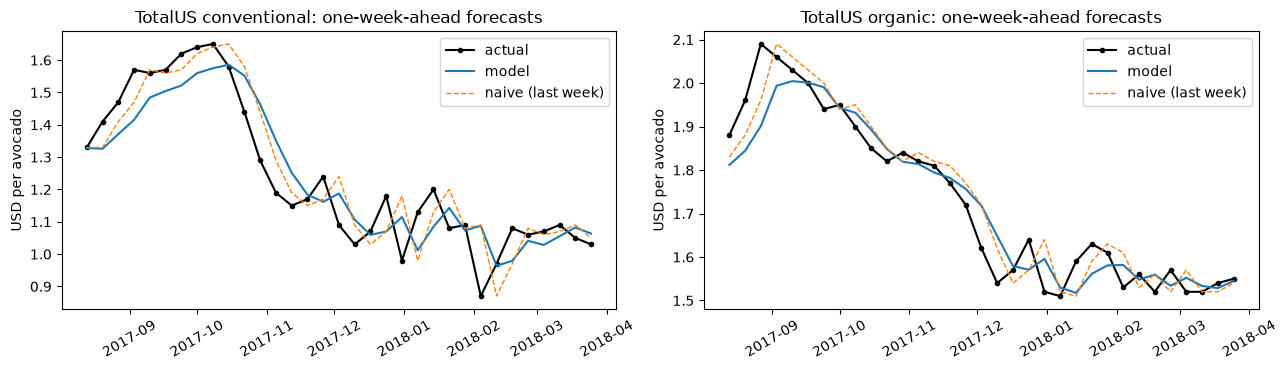

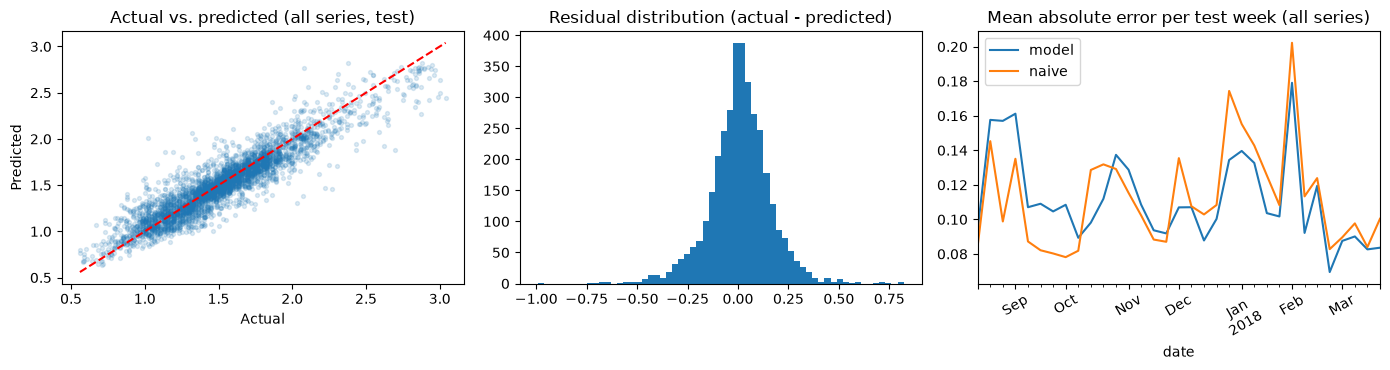

Residuals: mean 0.0098 | std 0.1528


In [19]:
# Actual vs. predicted over the test period (national series).
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for ax, kind in zip(axes, ["conventional", "organic"]):
    mask = test["region"].eq(SERVED_REGION) & test["type"].eq(kind)
    dates = test.loc[mask, DATE_COLUMN]
    ax.plot(dates, y_test[mask], "k-o", markersize=3, label="actual")
    ax.plot(dates, predictions[mask], "C0-", label="model")
    ax.plot(dates, test.loc[mask, "lag_1"], "C1--", linewidth=1,
            label="naive (last week)")
    ax.set_title(f"{SERVED_REGION} {kind}: one-week-ahead forecasts")
    ax.set_ylabel("USD per avocado")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
plt.tight_layout()
plt.show()

residuals = y_test - predictions
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(y_test, predictions, alpha=0.15, s=8)
limits = [min(y_test.min(), predictions.min()),
          max(y_test.max(), predictions.max())]
ax[0].plot(limits, limits, "r--")
ax[0].set_xlabel("Actual")
ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs. predicted (all series, test)")
ax[1].hist(residuals, bins=60)
ax[1].set_title("Residual distribution (actual - predicted)")
weekly = pd.DataFrame({
    "model": residuals.abs(),
    "naive": (y_test - test["lag_1"]).abs(),
}).groupby(test[DATE_COLUMN]).mean()
weekly.plot(ax=ax[2])
ax[2].set_title("Mean absolute error per test week (all series)")
ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print("Residuals: mean", round(residuals.mean(), 4), "| std",
      round(residuals.std(), 4))

num__week_sin            -0.0001
num__lag_3                0.0133
num__week_cos            -0.0167
cat__type_conventional   -0.0219
cat__type_organic         0.0219
num__lag_4                0.0291
num__diff_1               0.0344
num__roll_mean_4          0.0748
num__lag_2                0.1142
num__lag_1                0.1291
Name: Coefficients (standardized inputs), dtype: float64

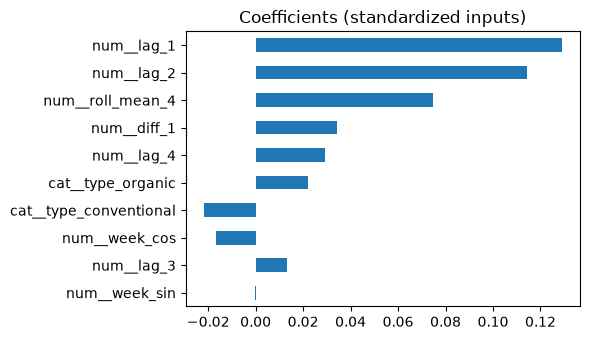

lag_1    0.571
lag_2    0.136
lag_3    0.082
lag_4    0.122
Name: weight of each past week, dtype: float64

Sum of the lag weights: 0.911
Organic minus conventional offset (USD): 0.044
Seasonal term: amplitude 0.024 USD, highest around week 26


In [20]:
# What the model learned: coefficients (linear) or importances (trees).
estimator = final_pipeline.named_steps["model"]
feature_names = final_pipeline.named_steps["prep"].get_feature_names_out()
if hasattr(estimator, "feature_importances_"):
    weights, title = estimator.feature_importances_, "Feature importance"
elif hasattr(estimator, "coef_"):
    weights, title = estimator.coef_, "Coefficients (standardized inputs)"
else:
    from sklearn.inspection import permutation_importance

    result = permutation_importance(
        final_pipeline, X_test, y_test, scoring=scoring, n_repeats=5,
        random_state=SEED,
    )
    feature_names = X_test.columns
    weights, title = result.importances_mean, "Permutation importance (RMSE)"
importance = pd.Series(weights, index=feature_names).sort_values(key=abs)
display(importance.round(4).rename(title))
importance.plot(kind="barh", figsize=(6, 3.5), title=title)
plt.tight_layout()
plt.show()

if hasattr(estimator, "coef_"):
    # roll_mean_4 and diff_1 are linear combinations of the four lags, so
    # their single coefficients cannot be read alone: fold everything into
    # one weight per past week, in USD of forecast per USD of past price.
    scaler = final_pipeline.named_steps["prep"].named_transformers_["num"]
    raw = pd.Series(
        estimator.coef_[:len(numeric_features)] / scaler.scale_,
        index=numeric_features,
    )
    lag_weights = pd.Series({
        f"lag_{k}": raw[f"lag_{k}"] + raw["roll_mean_4"] / N_LAGS
        for k in range(1, N_LAGS + 1)
    })
    lag_weights["lag_1"] += raw["diff_1"]
    lag_weights["lag_2"] -= raw["diff_1"]
    display(lag_weights.round(3).rename("weight of each past week"))
    print("Sum of the lag weights:", round(lag_weights.sum(), 3))
    by_name = pd.Series(estimator.coef_, index=feature_names)
    print("Organic minus conventional offset (USD):", round(
        by_name["cat__type_organic"] - by_name["cat__type_conventional"], 3
    ))
    amplitude = math.hypot(raw["week_sin"], raw["week_cos"])
    peak_week = (
        math.atan2(raw["week_sin"], raw["week_cos"]) / (2 * math.pi) * 52
    ) % 52
    print("Seasonal term: amplitude", round(amplitude, 3),
          "USD, highest around week", round(peak_week))

In [21]:
# Error analysis: where does the model beat the naive forecast?
errors = test[[DATE_COLUMN, "region", "type", "lag_1"]].copy()
errors["actual"] = y_test
errors["predicted"] = predictions
errors["model_sq"] = (errors["actual"] - errors["predicted"]) ** 2
errors["naive_sq"] = (errors["actual"] - errors["lag_1"]) ** 2


def rmse_table(keys):
    table = errors.groupby(keys)[["model_sq", "naive_sq"]].mean() ** 0.5
    table.columns = ["rmse_model", "rmse_naive"]
    table["skill_%"] = (1 - table["rmse_model"] / table["rmse_naive"]) * 100
    return table


display(rmse_table("type").round(4))
display(rmse_table(errors[DATE_COLUMN].dt.to_period("M")).round(4)
        .rename_axis("test month"))
per_series = rmse_table(["region", "type"])
print("Series where the model beats the naive forecast:",
      int((per_series["skill_%"] > 0).sum()), "of", len(per_series))
display(per_series["skill_%"].describe().round(2))
display(per_series.sort_values("skill_%").head(5).round(4))
display(per_series.sort_values("skill_%").tail(5).round(4))

# Size of the move: does the model help when the price jumps?
errors["abs_move"] = (errors["actual"] - errors["lag_1"]).abs()
errors["move"] = pd.cut(
    errors["abs_move"], [-0.001, 0.05, 0.15, np.inf],
    labels=["<= 0.05 USD", "0.05-0.15 USD", "> 0.15 USD"],
)
display(
    rmse_table("move").assign(n=errors.groupby("move", observed=True).size())
    .round(4)
)
print("Largest errors of the model:")
display(
    errors.assign(abs_error=errors["model_sq"] ** 0.5)
    .sort_values("abs_error", ascending=False)
    .head(5)[[DATE_COLUMN, "region", "type", "lag_1", "actual", "predicted"]]
    .round(3)
)

# Untuned candidate on the same test set, for reference only.
untuned_model = Pipeline([
    ("prep", clone(preprocessor)), ("model", clone(candidates[BEST])),
]).fit(X_train, y_train)
untuned_scores = scores(y_test, untuned_model.predict(X_test))
print("Untuned", BEST, "on test:",
      {key: round(value, 4) for key, value in untuned_scores.items()})

,rmse_model,rmse_naive,skill_%
type,,,
conventional,0.1513,0.1643,7.8604
organic,0.1548,0.1629,5.0095


,rmse_model,rmse_naive,skill_%
test month,,,
2017-08,0.1810,0.1533,-18.1048
2017-09,0.1526,0.1438,-6.0648
2017-10,0.1542,0.1614,4.5001
2017-11,0.1427,0.1411,-1.1606
2017-12,0.1465,0.1754,16.5053
2018-01,0.1700,0.1939,12.3641
2018-02,0.1635,0.1940,15.7487
2018-03,0.1137,0.1276,10.8717


Series where the model beats the naive forecast: 72 of 108


count    108.00
mean       3.17
std        8.35
min      -17.59
25%       -2.68
50%        4.05
75%       10.41
max       17.64
Name: skill_%, dtype: float64

,,rmse_model,rmse_naive,skill_%
region,type,,,
Nashville,organic,0.1233,0.1049,-17.5873
Southeast,organic,0.1104,0.0953,-15.9134
PhoenixTucson,conventional,0.1045,0.0910,-14.8182
SouthCarolina,organic,0.1010,0.0881,-14.6000
Atlanta,organic,0.1692,0.1488,-13.6632


,,rmse_model,rmse_naive,skill_%
region,type,,,
Albany,conventional,0.1828,0.2159,15.3595
California,organic,0.1491,0.1766,15.5887
SanFrancisco,conventional,0.2361,0.2824,16.3844
SanDiego,organic,0.1988,0.2408,17.4430
GrandRapids,conventional,0.2807,0.3409,17.6407


,rmse_model,rmse_naive,skill_%,n
move,,,,
<= 0.05 USD,0.0666,0.0258,-158.2882,1309
0.05-0.15 USD,0.1078,0.0961,-12.1705,1338
> 0.15 USD,0.2603,0.2993,13.0273,917


Largest errors of the model:


,date,region,type,lag_1,actual,predicted
2343,2018-01-07,RaleighGreensboro,organic,2.06,1.02,2.012
1073,2017-10-15,Tampa,organic,1.89,2.70,1.879
2677,2018-01-28,SanFrancisco,organic,1.36,2.27,1.455
2893,2018-02-11,SanFrancisco,organic,1.34,2.22,1.474
2461,2018-01-14,SanFrancisco,organic,2.30,1.32,2.064


Untuned Ridge on test: {'rmse': 0.1531, 'mae': 0.1114, 'mape': 7.7455, 'r2': 0.8501}


**Interpretation.** One-week-ahead forecasts on the 33 test weeks, which were not used in training:

| Test set | Forecast | RMSE (USD) | MAE (USD) | MAPE | R2 |
|---|---|---|---|---|---|
| All 108 series (3,564 forecasts) | **Model (Ridge)** | **0.1531** | 0.1114 | 7.75 % | 0.850 |
| | Naive (last week) | 0.1636 | 0.1124 | 7.98 % | 0.829 |
| | Mean of the last 4 weeks | 0.1764 | 0.1299 | 9.06 % | 0.801 |
| | Seasonal naive (52 weeks ago) | 0.4176 | 0.3212 | 20.24 % | -0.116 |
| National series `TotalUS` (66 forecasts) | Model (Ridge) | 0.0794 | 0.0618 | 4.57 % | 0.938 |
| | **Naive (last week)** | **0.0764** | 0.0591 | 4.49 % | 0.943 |

- **Over all the series the model beats the naive forecast:** RMSE 0.153 USD against 0.164 USD (6.4 % lower) and R2 0.850 against 0.829. MAE and MAPE are almost equal (0.111 against 0.112 USD; 7.7 % against 8.0 %), so the gain comes from reducing the large errors, not the typical error.
- **On the national series, which is the one the backend serves, the model does not beat the naive forecast:** RMSE 0.079 USD against 0.076 USD (3.9 % higher). The difference is 0.003 USD over 66 forecasts, too small to call either forecast better. The honest reading is that, for the national weekly price, **"same as last week" is as good as the trained model**. By type, the RMSE is 0.0951 against 0.0925 USD for conventional and 0.0597 against 0.0558 USD for organic, although for organic the model's MAE is slightly lower (0.0445 against 0.0461 USD). Cross-validation had already shown the same result.
- **The seasonal naive forecast is much worse** (RMSE 0.42 USD, negative R2): the price of the same week one year earlier is a poor guide, which is consistent with the change in price level between 2016 and 2017.
- Because the forecast is dominated by last week's price, both the model and the naive forecast tend to follow the actual price with a delay of one week, as expected of a one-step forecast of this kind.

**What the model learned.** `roll_mean_4` and `diff_1` are linear combinations of the lags, so the coefficients are combined into one weight per past week: **0.57** for last week and 0.14, 0.08 and 0.12 for the three weeks before. The weights add up to **0.91**, not 1, so the forecast is pulled slightly towards the average of the last month and towards the overall mean. The remaining terms are small: organic is 0.04 USD above conventional for the same recent prices, and the seasonal term has an amplitude of 0.02 USD, highest around week 26. The model is essentially a **smoothed, mean-reverting version of the naive forecast**.

**Error analysis:**
- **By size of the move:** when the price actually moved by more than 0.15 USD (917 forecasts), the model is better (RMSE 0.260 against 0.299 USD). When it moved by 0.05 USD or less (1,309 forecasts), the naive forecast is, by construction, almost exact (0.026 USD) and the model is not (0.067 USD). The model gives up some accuracy in calm weeks in exchange for smaller errors after jumps.
- **By series:** the model beats the naive forecast in **72 of the 108 series** (median gain 4 %; range from -18 % to +18 %). The largest gains are in regional series where the naive error is high (`GrandRapids`, `SanDiego`, `SanFrancisco`), and the largest losses are in series where it is low. The national series are among the smoothest, which explains the result above and matches section 3: the changes of the regional series are negatively autocorrelated (-0.26), while those of the national series are not.
- **By month:** the model was worse than the naive forecast in August and September 2017 (-18 % and -6 %), the months around the highest national prices of the dataset; about even in October and November (+5 % and -1 %); and better from December 2017 to March 2018 (+11 % to +17 %). This is consistent with a mean-reverting forecast: pulling towards the recent average hurts while the price keeps rising and helps when it falls back.
- **By type:** over all series the RMSE gain is 7.9 % for conventional and 5.0 % for organic.
- **Largest errors:** the five largest are all in regional organic series, with jumps of about 0.8 to 1 USD in one week (`RaleighGreensboro` from 2.06 to 1.02 USD; `Tampa` from 1.89 to 2.70 USD; `SanFrancisco` three times). In these cases the model's forecast stayed close to last week's price: the previous prices gave no sign of the jump.
- **Residuals:** centered (mean 0.01 USD), with a standard deviation of 0.15 USD; the largest errors, of both signs, come from those jumps.

**Effect of tuning.** None: the untuned Ridge, scored on the test set for reference only, has practically the same test metrics (RMSE 0.1531 USD, R2 0.8501).

**Possible causes of error:** one week ahead the price is close to a random walk, so most of the remaining error cannot be predicted from past prices alone; the inputs ignore supply (harvests, imports), promotions and volume; there are only three years of data, too few to learn the seasonality well; small organic markets show abrupt price changes; and the test period contains the highest national prices of the dataset.

## Export for the backend

In [22]:
# The exported pipeline is the evaluated one refitted on ALL the weeks, so
# the forecast of the next week uses the most recent data. The test metrics
# above belong to the pipeline fitted on the training weeks only.
export_pipeline = clone(final_pipeline).fit(data[FEATURES], data[target])
if hasattr(export_pipeline.named_steps["model"], "n_jobs"):
    export_pipeline.set_params(model__n_jobs=1)
joblib.dump(export_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib")

# History the adapter needs to build the lags without any user input: the
# last weeks of the national series of each type.
HISTORY_WEEKS = 8
last_date = weeks[-1]
forecast_date = last_date + pd.Timedelta(days=7)
history = {
    "region": SERVED_REGION,
    "last_date": str(last_date.date()),
    "dates": [str(d.date()) for d in weeks[-HISTORY_WEEKS:]],
    "prices": {
        kind: national[kind].iloc[-HISTORY_WEEKS:].round(2).tolist()
        for kind in sorted(national.columns)
    },
}
assert national.index[-1] == last_date

# The same call the adapter makes for "JarvisTEC, avocado price".
DEFAULT_TYPE = "conventional"
default_features = {}
default_predictions = {}
for kind, prices in history["prices"].items():
    default_features[kind] = build_features(prices, kind, forecast_date)
    default_predictions[kind] = round(float(export_pipeline.predict(
        pd.DataFrame([default_features[kind]])[FEATURES]
    )[0]), 4)

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": "time_series",
    "target": "average price of the next week, USD per avocado",
    "features": FEATURES,
    "n_lags": N_LAGS,
    "trained_on": "all (region, type) series; refitted on all weeks",
    "served_series": SERVED_REGION,
    "train_weeks": [str(train_weeks[0].date()), str(train_weeks[-1].date())],
    "test_weeks": [str(test_weeks[0].date()), str(test_weeks[-1].date())],
    "test_metrics": test_metrics,
    "naive_test_metrics": naive_metrics,
    "test_metrics_served_series": served_metrics,
    "naive_test_metrics_served_series": served_naive_metrics,
    "default_input": {"type": DEFAULT_TYPE},
    "history": history,
    "forecast_date": str(forecast_date.date()),
    "default_features": default_features,
    "expected_default_prediction": default_predictions[DEFAULT_TYPE],
    "expected_predictions": default_predictions,
    "sklearn_version": sklearn.__version__,
}
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

size_kb = (ARTIFACTS / f"{MODEL_NAME}.joblib").stat().st_size / 1024
print(f"Saved artifacts/{MODEL_NAME}.joblib ({size_kb:.0f} KB) and "
      f"{meta_path.name}")
print("Last observed week:", history["last_date"],
      "| forecast week:", meta["forecast_date"])
print("Last observed prices:",
      {kind: prices[-1] for kind, prices in history["prices"].items()})
print("Forecasts:", default_predictions)

Saved artifacts/avocado.joblib (3 KB) and avocado.meta.json
Last observed week: 2018-03-25 | forecast week: 2018-04-01
Last observed prices: {'conventional': 1.03, 'organic': 1.55}
Forecasts: {'conventional': 1.0523, 'organic': 1.5496}


## 6. Conclusion

A Ridge regression on the four previous weekly prices, the week of the year and the type forecasts next week's avocado price with a **test RMSE of 0.153 USD, MAE of 0.111 USD, MAPE of 7.7 % and R2 of 0.85** over the 108 series, against an RMSE of 0.164 USD for the naive forecast "same as last week" (6.4 % lower). **On the national series that JarvisTEC serves, it does not beat the naive forecast** (RMSE 0.079 against 0.076 USD, MAPE about 4.5 % for both). The honest conclusion is that the national weekly price is close to a random walk at a one-week horizon: the model is accurate (errors of about 6 cents), but nearly all of that accuracy comes from knowing last week's price. Its added value lies in the noisier regional series and in the weeks after a jump.

The exported pipeline is refitted on all 165 weeks (train + test) after the evaluation, so the test metrics above belong to the train-only fit and the exported model has no held-out score of its own. It is stored with the last eight national prices of each type. For the week of **2018-04-01**, the week after the last observation (2018-03-25), it forecasts **1.05 USD** for conventional (last price 1.03 USD) and **1.55 USD** for organic (last price 1.55 USD).

**Limitations:**
- The data ends in March 2018. The voice command forecasts the week after that date and says so; it is not a live price.
- On the served series the model is not better than repeating last week's price. The model was selected on the RMSE pooled over all the series, not on the national series, where the naive forecast was already ahead in cross-validation (0.0950 against 0.1007 USD).
- The best `alpha` (0.01) is the lowest value of the search grid, which was not extended, and only Ridge was tuned.
- It forecasts one week ahead only. Longer horizons would need the model's own forecasts as inputs, and the error would be expected to grow.
- The prices are US retail prices in USD per unit; they do not transfer to Costa Rica or to wholesale prices.
- There are only three years of data, so the seasonality and the behavior around the 2017 peak are learned from very few examples.
- The series overlap (cities inside regions inside the national total), so the 3,564 test forecasts are not independent and the pooled metrics look more precise than they are.

**Future improvements:**
- Add lagged supply information (last week's volume, imports, harvest calendars), the kind of signal that might beat the naive forecast.
- Use a longer history, to add lag-52 features and learn the seasonality.
- Forecast the change instead of the level, and give a prediction interval instead of a single value.
- Add classical time-series models such as exponential smoothing (ETS) and ARIMA as benchmarks; they are not included because `statsmodels` is not installed in the project environment.
- Refresh the stored history from a live source so that the command answers about the current week.

**Voice commands for this model:** *"JarvisTEC, avocado price"*, *"JarvisTEC, price of avocado"*, *"JarvisTEC, price of avocados"*, *"JarvisTEC, avocado forecast"*, *"JarvisTEC, how much will avocado cost"*, *"JarvisTEC, avocado"*. Saying "organic" or "conventional" in the command selects the type (for example *"JarvisTEC, organic avocado price"*).

### References

- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
- Makridakis, S., Spiliotis, E., & Assimakopoulos, V. (2018). Statistical and machine learning forecasting methods: Concerns and ways forward. *PLoS ONE, 13*(3), e0194889. https://doi.org/10.1371/journal.pone.0194889
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55-67.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- neuromusic. (n.d.). *Avocado Prices* [Data set]. Kaggle. https://www.kaggle.com/datasets/neuromusic/avocado-prices (according to the dataset description, compiled from Hass Avocado Board retail scan data)